<a href="https://colab.research.google.com/github/kimve1969/msu_ds_pinn_2d_heat/blob/3-%D1%80%D0%B0%D0%B7%D1%80%D0%B0%D0%B1%D0%BE%D1%82%D0%BE%D1%82%D0%B0%D1%82%D1%8C-pinn-%D0%BC%D0%BE%D0%B4%D0%B5%D0%BB%D1%8C-%D1%82%D0%B5%D0%BF%D0%BB%D0%BE%D0%BF%D1%80%D0%BE%D0%B2%D0%BE%D0%B4%D0%BD%D0%BE%D1%81%D1%82%D0%B8/msu-pinn-2d-heat.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Аттестационная работа по DS & ML - решение обратной коэффициентной задачи нестационарного 2D уравнения теплопередачи с применением алгоритмов DS & ML
#### МГУ, декабрь 2026, В.Е.Ким


## Постановка задачи:

Применение нейронной сети для решения обратной задачи физики процесса (PINN), описываемого дифференциальным уравнением, на примере нестационарного 2D уравнения теплопроводности (УТ) и его сравнение с численным методом МКР (метод конечной разности), взятым за эталон решения.

## Планируемое решение задачи по шагам:

1. Решение прямой задачи УТ с применением МКР неявным методом на 2D сетке с заданными граничными и начальными условиями Дирихле. Коэффициент температуропроводности $α$ (объединяет: теплопроводность, плотность, теплоемкость) задается матрицей в каждом узлу сетки (при расчете вычисляется гармонические коэффиценты $α$ между всеми узлами сетки). Исходная матрица $\alpha$ является искомой для последующего решения в обратной задаче с применением PINN.
2. Решение прямой задачи УТ с применением PINN. Матрицу $\alpha$ берем константную.
3. Решение обратной задачи УТ с применением PINN. Добавялем еще одну модель PINN которая будет аппроксимировать распределение коэффициентов $\alpha$ по пластине. В процессе обучения PINN будет сразу обучаться аппроксимировать физику с учетом распределения $\alpha$, таким образом сразу будет решаться обратная задача.
4. Решение обратной задачи УТ с применением суррогатной PINN. Суррогатная в смысле, что обученная PINN не дает сразу ответы по $\alpha$, будем обучать на разные варианты распределения $\alpha$ закономерность такого распределения заранее известна, например, пластина состоит из 4-х разных материалов, температуропроводность которых нах-ся в известном диапазоне. В отличие от шага 3, такой подход позволит почти мгновенно решать обратную задачу - по сути решать задачу оптимизации, либо с применением...
5. Проверка шагов 2,3,4 с аналогичной прямой задачей МКР, решенной на шаге 1.

# ШАГ 1
## Прямая задача решения 2D нестационарного уравнения теплопроводности методом конечной разности (МКР), неявная схема

Уравнение:
$$
\frac{\partial u}{\partial t} = \alpha(\frac{\partial^2 u}{\partial x^2} + \frac{\partial^2 u}{\partial y^2})
$$
где: $ α $ - коэф.температуропроводности, $\alpha = ρc$ , где $ \rho $ - плотность, $ c $ - теплоемкость.
Для решения диф. ур-ия, применим неявную схему (Backward Euler): \
$$ \frac{u_{i,j}^{n+1} - u_{i,j}^n}{\Delta t} = \alpha(A_x u_{i,j}^{n+1} + A_y u_{i,j}^{n+1}) $$
где: $ A_x, A_y $ - дискретные операторы Лапласа по направлениям: $ A_x u_{i,j} = \frac{u_{i-1,j} - 2u_{i,j} + u_{i+1,j}}{\Delta x^2} $, $ A_y u_{i,j} = \frac{u_{i,j-1} - 2u_{i,j} + u_{i,j+1}}{\Delta y^2} $

что приводит к СЛАУ:
$$ (I - \Delta t \cdot α \cdot A) u^{n+1} = u^n $$
где: I - единичный оператор (не единичная диагональная матрица!), A - дискретный оператор Лапласа (5-точечный шаблон)
для функции $u_{i,j}$ в узле сетки (i,j),
если $(Δx=Δy=h)$, то:
$
Au_{i,j}\approx \frac{u_{i-1,j}+u_{i+1,j}+u_{i,j-1}+u_{i,j+1}-4u_{i,j}}{h^2}
$
и шаблона оператора А выглядит так:
$$
A = \frac{1}{h^2}
\begin{bmatrix}
& 1 & \\
1 & -4 & 1\\
& 1 &
\end{bmatrix}
$$
если $ Δx \ne Δy $, то: $ Au_{i,j} ≈ \frac{u_{i-1,j} - 2u_{i,j} + u_{i+1,j}}{\Delta_x^2} + \frac{u_{i,j-1} - 2u_{i,j} + u_{i,j+1}}{\Delta_y^2} $ и шаблон опреатора А выглядит немного сложнее:
$$
A =
\begin{bmatrix}
& \frac{1}{Δy^2} & \\
\frac{1}{Δx^2} & -(\frac{2}{Δx^2} + \frac{2}{Δy^2}) & \frac{1}{Δx^2}\\
& \frac{1}{Δy^2} &
\end{bmatrix}
$$

Тогда оператор $M = (I - \Delta t \cdot α \cdot A)$ выглядит так:

$$
M = \Delta t \cdot α
\begin{bmatrix}
& -\frac{1}{Δy^2} & \\
-\frac{1}{Δx^2} & 1+(\frac{2}{Δx^2} + \frac{2}{Δy^2}) & -\frac{1}{Δx^2}\\
& -\frac{1}{Δy^2} &
\end{bmatrix}
$$


Ключевые моменты реализации

1. Разреженная пятидиагональная матрица M = I - dt*A строится один раз (она не меняется со временем).
2. LU-разложение через scipy.sparse.linalg.splu — вычисляется один раз, а затем на каждом шаге делается только обратная подстановка (очень быстро).
3. Индексация: узлы $(i,j)$, $i=1\ldots N_x$, $j=1\ldots N_y$ укладываются в вектор длины $N_xN_y$.
4. Граничные условия Дирихле учитываются неявно — они не входят в вектор неизвестных, а нулевые значения на границе дают нулевой вклад в правую часть.

Устойчивость: абсолютная \
Порядок по времени: $ O(\Delta t)$ \
Порядок по пространству: $O(\Delta x^2, \Delta y^2)$ \
Стоимость шага: $O(N_x N_y)$

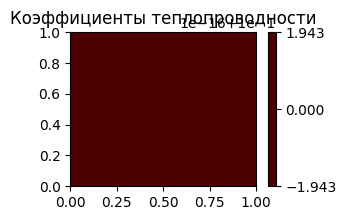

In [ ]:
from numpy._core.numeric import ndarray
import numpy as np
import torch
import scipy.sparse as sp
import scipy.sparse.linalg as spla
import time
import matplotlib.pyplot as plt

# ================================================================
# ОБЩИЕ ПАРАМЕТРЫ
# ================================================================
Lx, Ly, T_final = 1.0, 1.0, 1.0

# Сетка по x, y
Nx, Ny = 100, 100
dx = Lx / (Nx - 1)
dy = Ly / (Ny - 1)

x = np.linspace(0, Lx, Nx)
y = np.linspace(0, Ly, Ny)
X, Y = np.meshgrid(x, y, indexing='ij')

# Для неявной схемы ограничение на dt отсутствует, задаём из соображений точности
Nt = 100
t = np.linspace(0, T_final, Nt)
dt = T_final / (Nt-1)

# ============ Начальное условие (типа колокол) ============
def gic(x: np.ndarray | torch.TensorType, y: np.ndarray | torch.TensorType):
  if isinstance(x, np.ndarray):
    return np.exp(-30 * ((x - 0.5)**2 + (y - 0.5)**2))
  else:
    return torch.exp(-30 * ((x - 0.5)**2 + (y - 0.5)**2))

# ============ Граничные условия (нулевые - холодные стенки) ============
def apply_bc(u):
    # левый-верхний угол  # вверх             # правый-верхний угол
    u[0, -1] = 0.0;       u[1:-1, -1] = 0.0;  u[-1, -1] = 0.0;
    # левая сторона                           # правая сторона
    u[0, 1:-1] = 0.0;                         u[-1, 1:-1] = 0.0;
    # левый-нижний угол   # низ               # правый-нижний угол
    u[0, 0] = 0.0;        u[1:-1, 0] = 0.0;   u[-1, 0] = 0.0
    return u

# ============ Функция построения 2D-карты =====================
def plot2d(x_grid: np.ndarray, y_grid: np.ndarray, u_grid: np.ndarray, stitle: str):
  fig, ax = plt.subplots(figsize=(3, 2))
  #c = ax.contourf(x_grid, y_grid, u_grid, levels=100, cmap="hot", vmin=u_grid.min(), vmax=u_grid.max())
  c = ax.contourf(x_grid, y_grid, u_grid, levels=100, cmap="hot", vmin=0, vmax=1.0)
  plt.colorbar(c, ax=ax)
  plt.title(stitle)
  plt.show()

# ============ Визуализируем начальное состояние ========================
# u = gic(X,Y)
# u = apply_bc(u)
# plot2d(x_grid=X, y_grid=Y, u_grid=u, stitle="Начальное тепловое состояние")

# Формируем матрицу коэффициентов теплопроводности
# ============================================================
# 2. Четыре области-квадрата 2x2 со своими alhpa
#    (границы раздела: x=0.5 и y=0.5)
# ============================================================
alpha = np.zeros((Nx, Ny))
alpha[(X <  0.5) & (Y <  0.5)] = 0.1     # левый-нижний
alpha[(X >= 0.5) & (Y <  0.5)] = 0.1    # правый-нижний
alpha[(X <  0.5) & (Y >= 0.5)] = 0.1   # левый-верхний
alpha[(X >= 0.5) & (Y >= 0.5)] = 0.1     # правый-верхний

np.random.seed(42)
#alpha = np.random.rand(Nx, Ny)/3.0
# ============================================================
# 3. Эффективная alpha на гранях — гармоническое среднее
# ============================================================
alpha_x_eff = 2*alpha[:-1,:]*alpha[1:,:]/(alpha[:-1,:]+alpha[1:,:])   # (Nx-1, Ny)
alpha_y_eff = 2*alpha[:,:-1]*alpha[:,1:]/(alpha[:,:-1]+alpha[:,1:])   # (Nx, Ny-1)

# ============ Визуализируем коэффициентов теплопроводности ==============
plot2d(x_grid=X, y_grid=Y, u_grid=alpha, stitle="Коэффициенты теплопроводности")

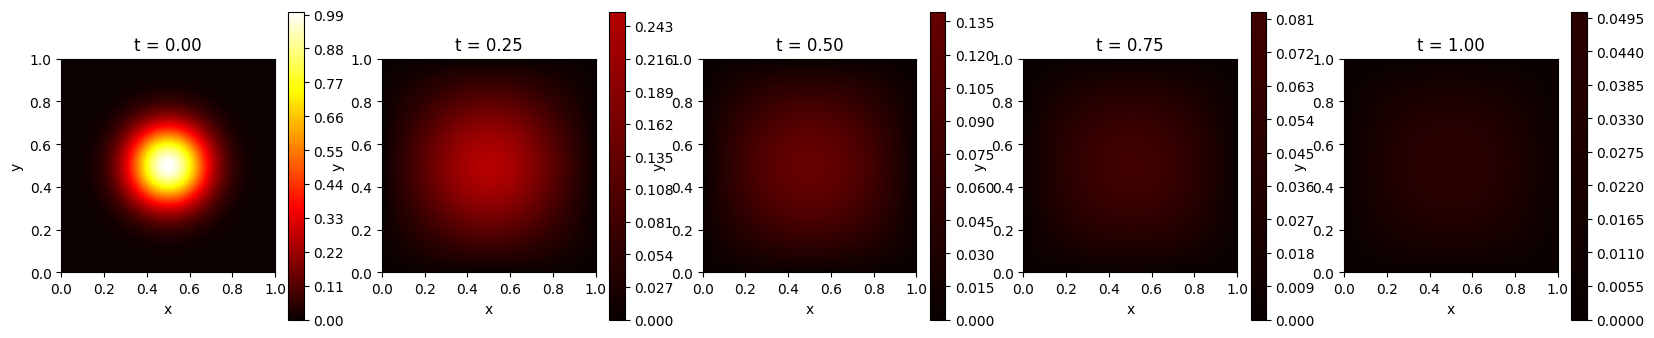

In [ ]:
# Упорядочим неизвестные построчно: индекс k = i*Ny + j
# (i = 1..Nx-2, j = 1..Ny-2 - внутренние узлы)

ax_coef = alpha_x_eff * dt / dx**2
ay_coef = alpha_y_eff * dt / dy**2

# Разреженную матрицы системы M = I - dt*A будем представлять в виде 3-х векторов
rows, cols, data = [], [], []

# ================================================================
# НУМЕРАЦИЯ ВСЕХ УЗЛОВ (внутренних + граничных)
# ================================================================
def idx(i, j):
    """
    Линейный индекс idx для векторов rows, cols, data
    рассчитанный по индексам внутреннего узла M(i,j), i=0..Nx-1, j=0..Ny-1
    """
    return i * Ny + j

# упаковываем в три вектора согласно оператору M = I - dt*A (см.выше)
# узлы внутренней области: (1:Nx-2) x (1:Ny-2)
for i in range(Nx):
    for j in range(Ny):
        k = idx(i, j)

        if i==0 or i==(Nx-1) or j==0 or j==(Ny-1):
            # граничная строка: 1·u_k = g_k
            rows.append(k);
            cols.append(k);
            data.append(1.0)
            continue
        # внутренние узлы

        # alpha_x_eff[i,j] размерностью (Nx-1,Ny) эффективная \alhpa
        # между гранями (i,j) и (i+1,j), т.е. движемся вправо, узлов Nx,
        # граней Nx, аналогично
        # alpha_y_eff[i,j] размерностью (Nx, Ny-1) эффективная \alpha
        # между гранями (i,j) и (i,j+1), т.е. движемся вверх
        #
        # Для внутреннего узла (i,j) нужны 2 грани по х:
        # (i-1,j)-(i,j) и (i,j)-(i+1,j), т.е. alpha_x_eff[i-1,j] и alpha_x_eff[i,j]
        # и 2 грани по y:
        # (i,j-1)-(i,j) и (i,j)-(i,j+1), т.е. alpha_y_eff[i,j-1] и alpha_y_eff[i,j]
        #
        ax_w = ax_coef[i - 1, j]   # грань (i-1,j)-(i,j)
        ax_e = ax_coef[i,     j]   # грань (i,j)-(i+1,j)
        ay_s = ay_coef[i, j - 1]   # грань (i,j-1)-(i,j)
        ay_n = ay_coef[i, j    ]   # грань (i,j)-(i,j+1)
        # диагональ
        rows.append(k);
        cols.append(k)
        data.append(1.0 + ax_w + ax_e + ay_s + ay_n)
        # отрабатываем соседние узлы
        # сосед слева (i-1, j)
        rows.append(k);
        cols.append(idx(i - 1, j));
        data.append(-ax_w)
        # сосед справа (i+1, j)
        rows.append(k);
        cols.append(idx(i + 1, j));
        data.append(-ax_e)
        # сосед снизу (i, j-1)
        rows.append(k);
        cols.append(idx(i, j - 1));
        data.append(-ay_s)
        # сосед сверху (i, j+1)
        rows.append(k);
        cols.append(idx(i, j + 1));
        data.append(-ay_n)

M = sp.csr_matrix((data, (rows, cols)), shape=(Nx * Ny, Nx * Ny))
# M.shape - логический размер матрицы, при этом сами данные лежат в трех векторах
# M = sp.csr_matrix((data, (rows, cols)))
# print(f"Логический размер CSR-матрицы: {M.shape}, кол-во ненулевых элементов: {M.nnz}")

# LU разложение матрицы
# т.е. ур-ие вида Ax=b, решаем как PAQ=LU, где:
# P,Q - матрицы перестановок строк и столбцов
# L,U - нижне и верхне треугольные матрицы
# получаем объект SuperLU, у которого есть метод solve()
# для подстановки правой части b и есть .L, .U
solve = spla.splu(M.tocsc())

# ============ Решение по времени ============
save_times = [0.0, 0.25, 0.5, 0.75, 1.0]
# сюда сохраняем матрицу решений
solutions = []
# сюда записываем номер шага по времени
save_indices = [int(round(t / dt)) for t in save_times ]

# применяем начальные и граничные условия
u = gic(X,Y)
u = apply_bc(u)

for n in range(Nt + 1):
    if n in save_indices:
        solutions.append(u.copy())
    if n == Nt:
        break
    # правая часть - текущее решение во внутренних узлах
    # вытягиваем матрицу в вектор, order="C" - порядок языка СИ
    # т.е. в u[i,j] идем вначале по j, потом по i
    b = u.reshape(-1, order="C")
    # решаем СЛАУ, где b = u^{n}, sol=u^{n+1}
    sol = solve.solve(b)
    # обновляем внутренние узлы
    # обратная операция перепаковываем вектор в матрицу
    u = sol.reshape((Nx, Ny), order="C")
    # граничные условия
    u = apply_bc(u)

# ============ Визуализация в контрольные моменты ============
fig, axes = plt.subplots(1, len(solutions), figsize=(4 * len(solutions), 4))
if len(solutions) == 1:
    axes = [axes]

for ax, t, sol in zip(axes, save_times, solutions):
    im = ax.contourf(X, Y, sol, levels=100, cmap="hot", vmin=0, vmax=1.0)
    ax.set_title(f"t = {t:.2f}")
    ax.set_xlabel("x")
    ax.set_ylabel("y")
    ax.set_aspect("equal")
    plt.colorbar(im, ax=ax)

plt.show()

In [ ]:
# Создаем нейросеть 3(x,y,t)->100->100->1
import numpy as np
import torch
import torch.nn as nn

class Nu( nn.Module ):
    def __init__(self):
        super().__init__()
        self.fc = nn.Sequential(
            nn.Linear(3,64),
            nn.Tanh(),
            nn.Linear(64,128),
            nn.Tanh(),
            nn.Linear(128,128),
            nn.Tanh(),
            nn.Linear(128,64),
            nn.Tanh(),
            nn.Linear(64,1)
        )

    def forward(self, x: torch.tensor, y: torch.tensor, t: torch.tensor):
        return self.fc( torch.cat([x, y, t], dim=1) ) # self.layers()


def build_collocate_points(n_pde: int=10000, n_bc: int=5000, n_ic: int=2000):
  '''
  Функция создания точек коллокаций в заданом кубе: [1,1,1]

  Входный параметры: n_pde,n_bc,n_ic - кол-во случайных точек по х,y,t

  Возвращаемое значение: кортеж(кортеж_нач_усл, кортеж_гр_усл, кортеж_внутр_обл)
  каждый из внутренних кортежей имеет структру: (x, y, t)
  каждый из которых является вектор-столбом - torch.tensor.view(-1,1)
  '''
  # кортежи (x,y,t)
  # точки коллокации для начальных условий (x,y,0)
  points_ic = (torch.rand(n_ic, 1, requires_grad=True, dtype=torch.double),
               torch.rand(n_ic, 1, requires_grad=True, dtype=torch.double),
               torch.zeros(n_ic, 1, requires_grad=True, dtype=torch.double))
  # точки коллокации для граничных условий
  x = torch.rand(n_bc, 1, requires_grad = True, dtype=torch.double)
  y = torch.rand(n_bc, 1, requires_grad = True, dtype=torch.double)
  t = torch.rand(n_bc, 1, requires_grad = True, dtype=torch.double)

  border_selector = torch.randint(0, 4, (n_bc, 1))
  with torch.no_grad():
    x[border_selector == 0] = 0.0   # Левая грань
    x[border_selector == 1] = 1.0   # Правая грань
    y[border_selector == 2] = 0.0   # Нижняя грань
    y[border_selector == 3] = 1.0   # Верхняя грань

  points_bc = (x, y, t)
  # точки коллокации для внутренней области (x,y,t)
  points_pde = (torch.rand(n_pde, 1, requires_grad=True, dtype=torch.double),
                torch.rand(n_pde, 1, requires_grad=True, dtype=torch.double),
                torch.rand(n_pde, 1, requires_grad=True, dtype=torch.double))

  return (points_pde, points_bc, points_ic)

# Функция генерирующая граничные условия по векторам (x,y,t)
def gbc(x: torch.TensorType, y: torch.TensorType, t: torch.TensorType):
  return torch.zeros_like(x)

points_pde, points_bc, points_ic = build_collocate_points(n_pde = 3000, n_bc=5000, n_ic=10000)

In [ ]:
import os
import multiprocessing

print('Logical CPUs:', os.cpu_count())
print('multiprocessing:', multiprocessing.cpu_count())

torch.set_num_threads(8)

In [ ]:
import time
u_net = Nu().double()
optimizer = torch.optim.Adam( u_net.parameters(), lr=1e-2 )
mse_loss = nn.MSELoss()

# параметры для расчета loss_pde
k = 0.1
# весовые коэффициенты для общего loss
w_pde, w_ic, w_bc = 1.,1.,1.
# обучение
MAX = 1000

loss_history = {'pde': [],
                'ic': [],
                'bc': []}

for epoch in range(MAX):
    start = time.perf_counter()
    # стираем предыдущий граф градиента
    optimizer.zero_grad()
    # ---------------------------------- LOSS PDE ----------------
    u_pred_pde = u_net(points_pde[0], points_pde[1], points_pde[2])
    # du/dx, du/dy, du/dt
    du_dx, du_dy, du_dt = torch.autograd.grad(u_pred_pde,
                                         # векторы x,y,t
                                         inputs=[points_pde[0], points_pde[1], points_pde[2]],
                                         grad_outputs=torch.ones_like(u_pred_pde),
                                         create_graph=True, retain_graph=True)
    # d2u/dx2
    d2u_dx2 = torch.autograd.grad(du_dx,
                                    inputs=[points_pde[0]],
                                    grad_outputs=torch.ones_like(du_dx),
                                    create_graph=True, retain_graph=True)[0]
    # d2u/dy2
    d2u_dy2 = torch.autograd.grad(du_dy,
                                    inputs=[points_pde[1]],
                                    grad_outputs=torch.ones_like(du_dy),
                                    create_graph=True, retain_graph=True)[0]
    # loss pde
    loss_pde = mse_loss( du_dt - k*(d2u_dx2 + d2u_dy2),
                         torch.zeros_like(du_dt))
    # ---------------------------------- LOSS IC -----------------
    u_pred_ic = u_net(points_ic[0], points_ic[1], points_ic[2])
    loss_ic = mse_loss(u_pred_ic,
                       gic(points_ic[0], points_ic[1]))
    # ---------------------------------- LOSS BC -----------------
    u_pred_bc = u_net(points_bc[0], points_bc[1], points_bc[2])
    loss_bc = mse_loss(u_pred_bc,
                       gbc(points_bc[0], points_bc[1], points_bc[2]))
    # ---------------------------------- LOSS COMMON -------------
    loss = w_pde * loss_pde + w_ic * loss_ic + w_bc * loss_bc

    # обратное распространение ошибки
    loss.backward()
    # записываем новые коэфициента
    optimizer.step()

    loss_history['ic'].append(loss_ic.item())
    loss_history['bc'].append(loss_bc.item())
    loss_history['pde'].append(loss_pde.item())

    if epoch % 20 == 0:
        print(f'Epoch [{epoch}/{MAX}], Loss: {loss.item():.8f}, loss pde: {loss_pde.item():.8f}, loss ic: {loss_ic.item():.8}, loss bc: {loss_bc.item():.8f}, time: {(time.perf_counter() - start):.8f}')
    if loss < 0.00001:
        print('stop optimization')
        break

Epoch [0/1000], Loss: 0.05560151, loss pde: 0.00011405, loss ic: 0.055120053, loss bc: 0.00036740
Epoch [20/1000], Loss: 0.05875108, loss pde: 0.00305520, loss ic: 0.054910334, loss bc: 0.00078555
Epoch [40/1000], Loss: 0.04705823, loss pde: 0.00001962, loss ic: 0.044579995, loss bc: 0.00245862
Epoch [60/1000], Loss: 0.04645507, loss pde: 0.00033334, loss ic: 0.043846569, loss bc: 0.00227516
Epoch [80/1000], Loss: 0.04619830, loss pde: 0.00055943, loss ic: 0.043507029, loss bc: 0.00213184
Epoch [100/1000], Loss: 0.04577021, loss pde: 0.00041682, loss ic: 0.043033493, loss bc: 0.00231990
Epoch [120/1000], Loss: 0.04494588, loss pde: 0.00042000, loss ic: 0.042482064, loss bc: 0.00204381
Epoch [140/1000], Loss: 0.04307966, loss pde: 0.00047647, loss ic: 0.040936526, loss bc: 0.00166666
Epoch [160/1000], Loss: 0.03837791, loss pde: 0.00085052, loss ic: 0.03633154, loss bc: 0.00119585
Epoch [180/1000], Loss: 0.03250265, loss pde: 0.00142791, loss ic: 0.030272998, loss bc: 0.00080174
Epoch [

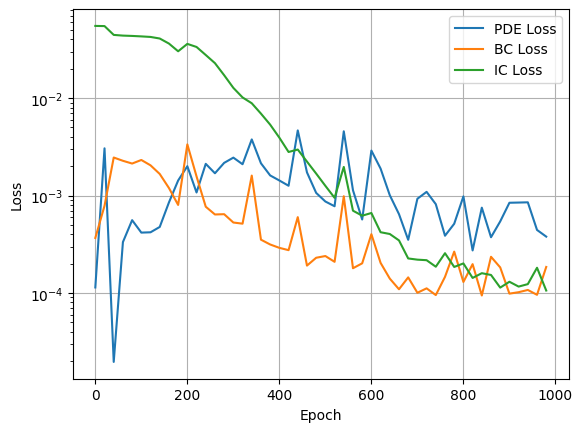

In [ ]:
def plot_loss_history(loss_history: dict,
                      step: int=200):
    """
    Функция для построения графика функции потерь.

    Parameters
    ----------
    loss_history : dict
        Словарь, содержащий данные для потерь.
    step : int, optional
        Шаг выборки данных для отображения, по умолчанию 100.
    """
    epochs = range(0, len(loss_history['pde']), step)

    plt.plot(epochs, loss_history['pde'][::step], label='PDE Loss')
    plt.plot(epochs, loss_history['bc'][::step], label='BC Loss')
    plt.plot(epochs, loss_history['ic'][::step], label='IC Loss')

    plt.yscale('log')
    plt.xlabel('Epoch')
    plt.ylabel('Loss')
    plt.grid()
    plt.legend()
    plt.show()


plot_loss_history(loss_history, 20)

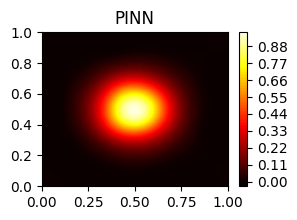

In [ ]:
u_pred_pinn = u_net( torch.tensor(X).view(-1,1),
                     torch.tensor(Y).view(-1,1),
                     torch.zeros_like( torch.tensor(X).view(-1,1)))

plot2d(x_grid=X, y_grid=Y, u_grid=u_pred_pinn.view(100,100).detach().numpy(), stitle="PINN")

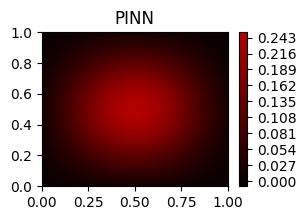

In [ ]:
u_pred_pinn = u_net( torch.tensor(X).view(-1,1),
                     torch.tensor(Y).view(-1,1),
                     torch.ones_like( torch.tensor(X).view(-1,1)) * .25)

plot2d(x_grid=X, y_grid=Y, u_grid=u_pred_pinn.view(100,100).detach().numpy(), stitle="PINN")

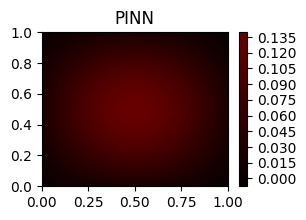

In [ ]:
u_pred_pinn = u_net( torch.tensor(X).view(-1,1),
                     torch.tensor(Y).view(-1,1),
                     torch.ones_like( torch.tensor(X).view(-1,1)) * .5)

plot2d(x_grid=X, y_grid=Y, u_grid=u_pred_pinn.view(100,100).detach().numpy(), stitle="PINN")

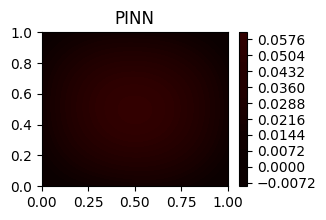

In [ ]:
u_pred_pinn = u_net( torch.tensor(X).view(-1,1),
                     torch.tensor(Y).view(-1,1),
                     torch.ones_like( torch.tensor(X).view(-1,1)) * 1.0)

plot2d(x_grid=X, y_grid=Y, u_grid=u_pred_pinn.view(100,100).detach().numpy(), stitle="PINN")

## Экспорт модели в формат ONNX

In [ ]:
#!pip install onnx
!pip install onnxscript

#import onnx
def export_to_onnx():
  torch.onnx.export(u_net,
                  (torch.randn(1, 1, dtype=torch.float64) * 1.0,
                   torch.randn(1, 1, dtype=torch.float64) * 1.0,
                   torch.randn(1, 1, dtype=torch.float64) * 1.0),
                  "msu-pinn-2d-heat.onnx",
                  opset_version=1,
                  input_names=['x', 'y', 't'],
                  output_names=['u'])

export_to_onnx()

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 754.2/754.2 kB 8.8 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8.9/8.9 MB 61.4 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3/3 [onnxscript]


/tmp/ipykernel_6281/2409524204.py:6: UserWarning: Exporting a model while it is in training mode. Please ensure that this is intended, as it may lead to different behavior during inference. Calling model.eval() before export is recommended.
  torch.onnx.export(u_net,
W1108 18:16:56.584000 6281 torch/onnx/_internal/exporter/_compat.py:133] Setting ONNX exporter to use operator set version 18 because the requested opset_version 1 is a lower version than we have implementations for. Automatic version conversion will be performed, which may not be successful at converting to the requested version. If version conversion is unsuccessful, the opset version of the exported model will be kept at 18. Please consider setting opset_version >=18 to leverage latest ONNX features


[torch.onnx] Obtain model graph for `Nu([...]` with `torch.export.export(..., strict=False)`...
[torch.onnx] Obtain model graph for `Nu([...]` with `torch.export.export(..., strict=False)`... ✅
[torch.onnx] Run decompositions...


Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/onnxscript/version_converter/__init__.py", line 137, in call
    converted_proto = _c_api_utils.call_onnx_api(
        func=_partial_convert_version, model=model
    )
  File "/usr/local/lib/python3.13/dist-packages/onnxscript/version_converter/_c_api_utils.py", line 65, in call_onnx_api
    result = func(proto)
  File "/usr/local/lib/python3.13/dist-packages/onnxscript/version_converter/__init__.py", line 132, in _partial_convert_version
    return onnx.version_converter.convert_version(
           ~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~^
        proto, target_version=self.target_version
        ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
    )
    ^
  File "/usr/local/lib/python3.13/dist-packages/onnx/version_converter.py", line 39, in convert_version
    converted_model_str = C.convert_version(model_str, target_version)
RuntimeError: /project/onnx/version_converter/BaseConverter.h:66: adapter_lookup: Ass

[torch.onnx] Run decompositions... ✅
[torch.onnx] Translate the graph into ONNX...
[torch.onnx] Translate the graph into ONNX... ✅
[torch.onnx] Optimize the ONNX graph...
[torch.onnx] Optimize the ONNX graph... ✅
